# Part 1: Data Understanding and Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

# Load dataset

In [ ]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


# Dataset Analysis

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df.describe(include="object")

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


# Check Missing Values

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df["TotalCharges"].value_counts().head()

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [ ]:
print(df["TotalCharges"].isnull().sum())

11


# Habdle missing value with media

In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df = df.drop("customerID", axis=1)

# Explore Churn Distribution

In [ ]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
print(
    df["Churn"].value_counts(normalize=True) * 100
)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


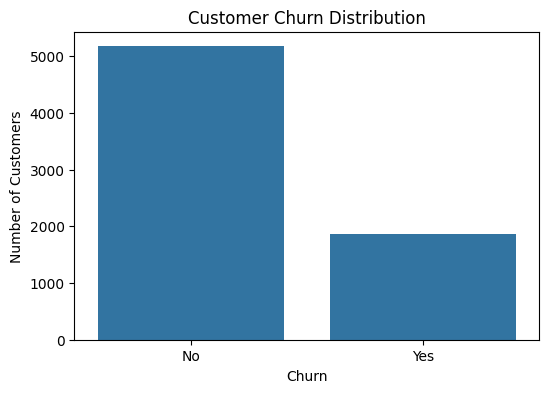

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

 dataset is not perfectly balanced. There are considerably more customers who do not churn than customers who churn.

So, accuracy alone should not be used to judge the models. Precision, recall, F1-score, and ROC-AUC are also important.

# Churn vs Contract

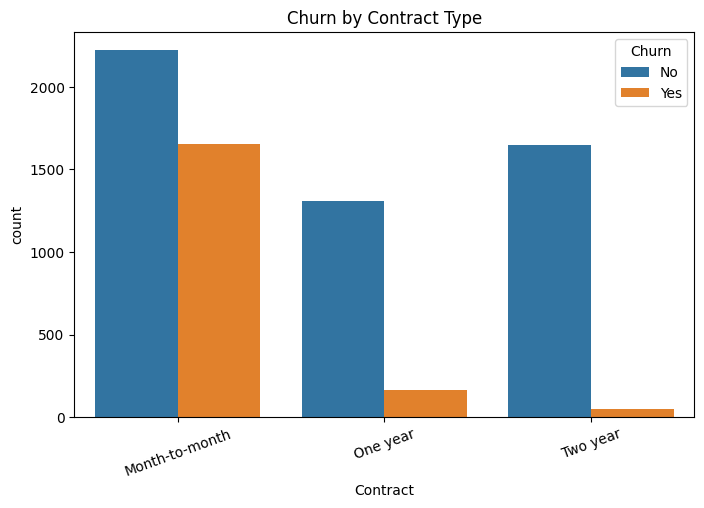

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.xticks(rotation=20)

plt.show()

Customers with month-to-month contracts generally have higher churn than customers with one-year or two-year contracts.

# Churn vs Tenure

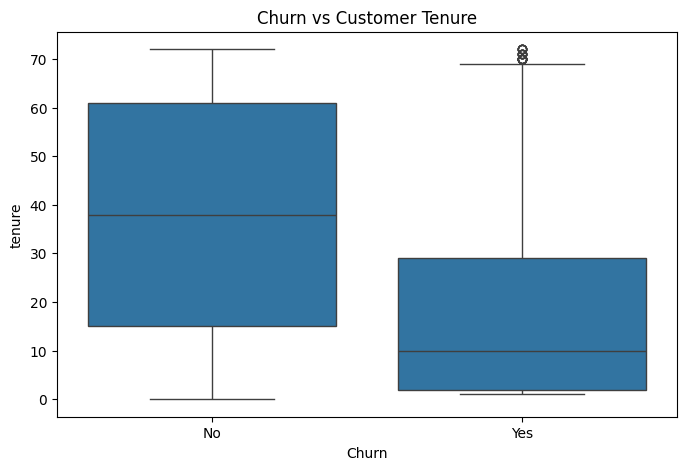

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Churn vs Customer Tenure")

plt.show()

Customers who churn tend to have shorter tenure, while long-term customers are generally more likely to remain.

# Churn vs Monthly Charges

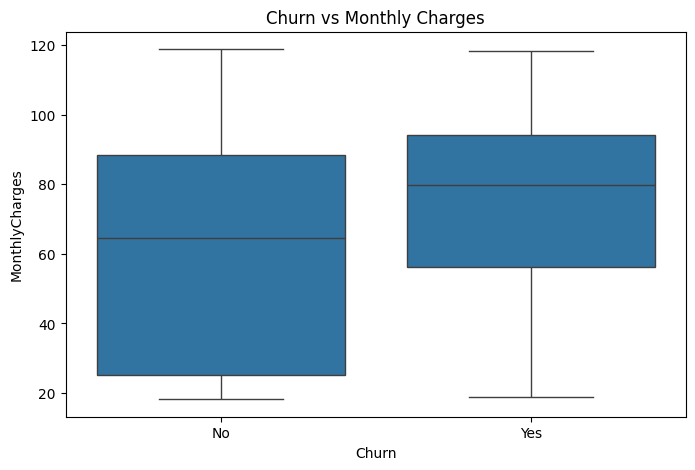

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Churn vs Monthly Charges")

plt.show()

Higher monthly charges can be associated with increased churn risk.

# Convert Target Variable

In [ ]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [ ]:
df["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


# Separate Features and Target

In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical features:")
print(list(numeric_features))

print("\nCategorical features:")
print(list(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


# Preprocessing

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

Catagorical value -> one hot encoding

numerical value -> KNN , Logistic Regression

# Train Logistic Regression

In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# K-Nearest Neighbors

In [ ]:
k_values = [3, 5, 7, 9]

knn_results = []

for k in k_values:

    knn_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    knn_model.fit(X_train, y_train)

    pred = knn_model.predict(X_test)
    prob = knn_model.predict_proba(X_test)[:, 1]

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

knn_results_df = pd.DataFrame(knn_results)

knn_results_df

,K,Accuracy,Precision,Recall,F1,ROC-AUC
0,3,0.755145,0.538058,0.548128,0.543046,0.747020
1,5,0.766501,0.559682,0.564171,0.561917,0.792631
2,7,0.767211,0.563187,0.548128,0.555556,0.802224
3,9,0.775727,0.578378,0.572193,0.575269,0.810436


 1. Small K → more sensitive to individual observations and noise.

 2. Large K → smoother predictions but may underfit.

 3. Scaling is important because KNN relies on distance.


# Train Decision Tree

In [ ]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=10,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Experiment with Tree Depth

In [ ]:
depths = [3, 5, 7, 10, None]

dt_results = []

for depth in depths:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=10,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    dt_results.append({
        "Max Depth": str(depth),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

dt_results_df = pd.DataFrame(dt_results)

dt_results_df

,Max Depth,Accuracy,Precision,Recall,F1,ROC-AUC
0,3,0.787083,0.668182,0.393048,0.494949,0.816766
1,5,0.795600,0.631902,0.550802,0.588571,0.828694
2,7,0.799148,0.645367,0.540107,0.588064,0.820773
3,10,0.775018,0.595318,0.475936,0.528975,0.791697
4,None,0.775727,0.596667,0.478610,0.531157,0.779161


Very small depth → Underfitting

Moderate depth → Better generalization

Very large depth → Overfitting


# Random Forest



In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Tune Random Forest

In [ ]:
rf_configs = [
    (100, 5, "sqrt"),
    (200, 10, "sqrt"),
    (300, 15, "sqrt"),
    (200, None, "sqrt")
]

rf_results = []

for n, depth, features in rf_configs:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            max_features=features,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    rf_results.append({
        "n_estimators": n,
        "max_depth": depth,
        "max_features": features,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

rf_results_df = pd.DataFrame(rf_results)

rf_results_df

,n_estimators,max_depth,max_features,Accuracy,Precision,Recall,F1,ROC-AUC
0,100,5.0,sqrt,0.792051,0.678414,0.411765,0.512479,0.840329
1,200,10.0,sqrt,0.805536,0.670068,0.526738,0.589820,0.843283
2,300,15.0,sqrt,0.794180,0.639073,0.516043,0.571006,0.830871
3,200,NaN,sqrt,0.792051,0.639175,0.497326,0.559398,0.825852


# Model Evaluation

In [ ]:
def evaluate_model(name, y_true, y_pred, y_prob):

    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

# Evaluate All Models

In [ ]:
best_knn = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=7))
])

best_knn.fit(X_train, y_train)

y_pred_knn = best_knn.predict(X_test)
y_prob_knn = best_knn.predict_proba(X_test)[:, 1]

In [ ]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_lr,
        y_prob_lr
    )
)

results.append(
    evaluate_model(
        "KNN",
        y_test,
        y_pred_knn,
        y_prob_knn
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt,
        y_prob_dt
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf,
        y_prob_rf
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,TN,FP,FN,TP
0,Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.842006,926,109,165,209
1,KNN,0.767211,0.563187,0.548128,0.555556,0.802224,876,159,169,205
2,Decision Tree,0.795600,0.631902,0.550802,0.588571,0.828694,915,120,168,206
3,Random Forest,0.805536,0.670068,0.526738,0.589820,0.843283,938,97,177,197


# Confusion Matrix

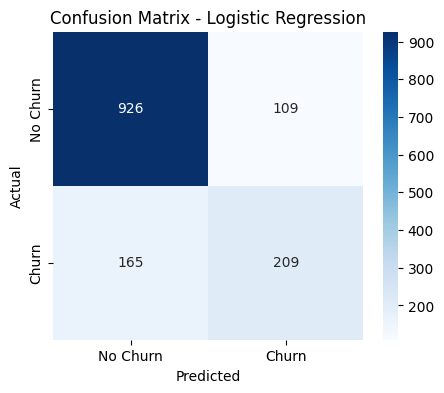

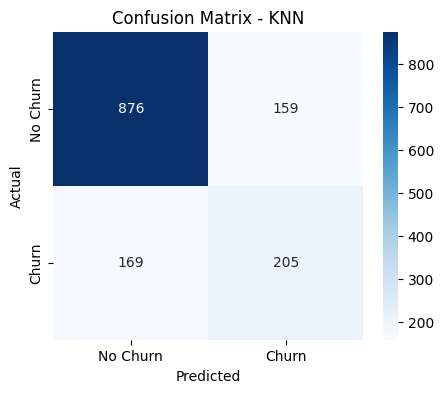

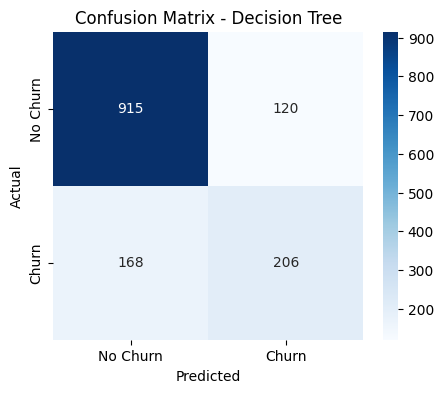

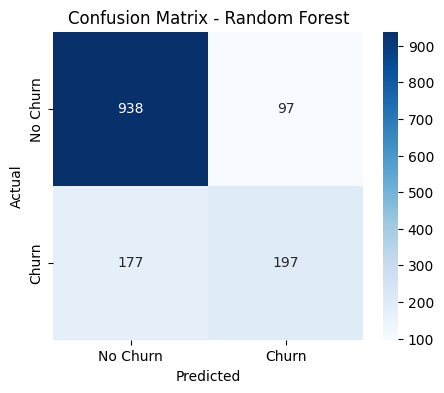

In [ ]:
models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "KNN": (y_pred_knn, y_prob_knn),
    "Decision Tree": (y_pred_dt, y_prob_dt),
    "Random Forest": (y_pred_rf, y_prob_rf)
}

for name, (pred, prob) in models.items():

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

# Classification Report

In [ ]:
for name, (pred, prob) in models.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            pred,
            target_names=["No Churn", "Churn"]
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

KNN
              precision    recall  f1-score   support

    No Churn       0.84      0.85      0.84      1035
       Churn       0.56      0.55      0.56       374

    accuracy                           0.77      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409

Decision Tree
              precision    recall  f1-score   support

    No Churn       0.84      0.88      0.86      1035
       Churn       0.63      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80   

# ROC CURVE

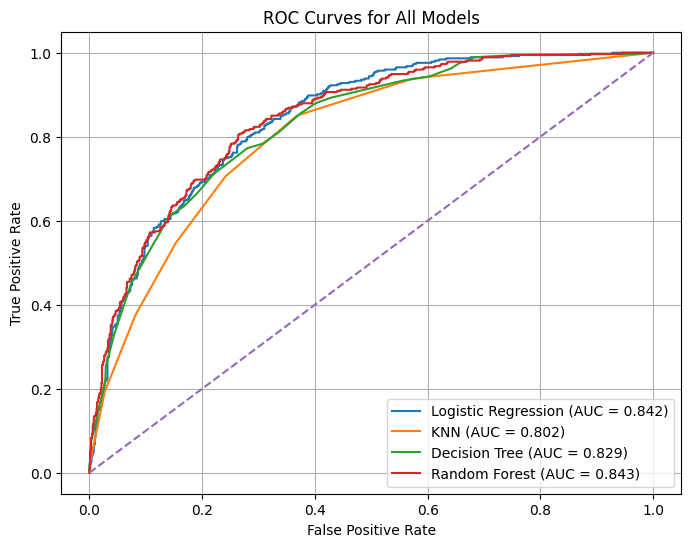

In [ ]:
plt.figure(figsize=(8,6))

for name, (pred, prob) in models.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        prob
    )

    auc = roc_auc_score(
        y_test,
        prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All Models")

plt.legend()
plt.grid()

plt.show()

# Feature Importance — Decision Tree

In [ ]:
dt_preprocessor = dt_model.named_steps["preprocessor"]

feature_names = dt_preprocessor.get_feature_names_out()

dt_classifier = dt_model.named_steps["classifier"]

dt_importance = pd.Series(
    dt_classifier.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

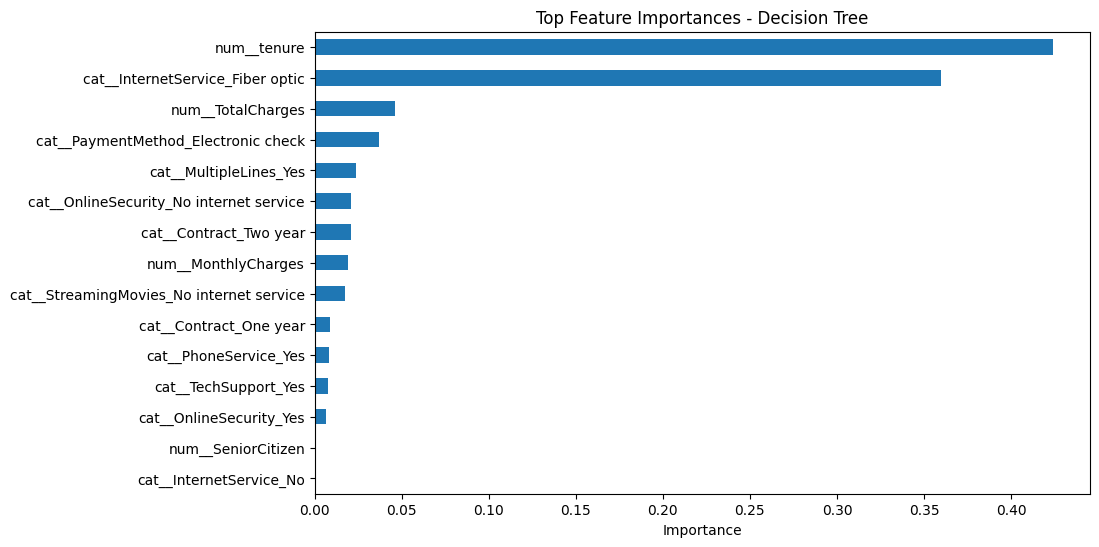

In [ ]:
plt.figure(figsize=(10,6))

dt_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top Feature Importances - Decision Tree")
plt.xlabel("Importance")

plt.show()

# RF

In [ ]:
rf_preprocessor = rf_model.named_steps["preprocessor"]

rf_feature_names = rf_preprocessor.get_feature_names_out()

rf_classifier = rf_model.named_steps["classifier"]

rf_importance = pd.Series(
    rf_classifier.feature_importances_,
    index=rf_feature_names
).sort_values(ascending=False)

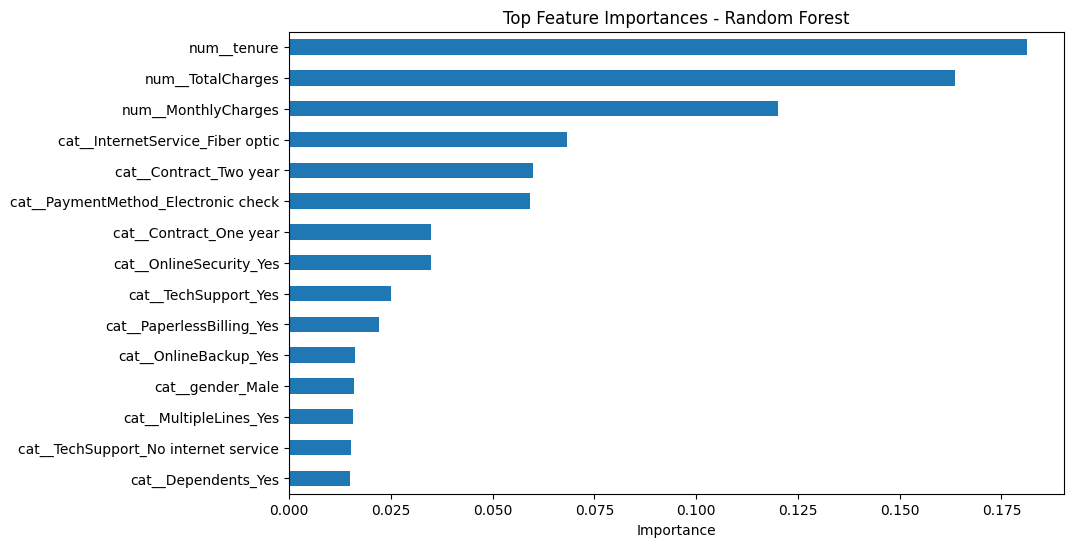

In [ ]:
plt.figure(figsize=(10,6))

rf_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top Feature Importances - Random Forest")
plt.xlabel("Importance")

plt.show()

# Conclusion :

Among the four models, Logistic Regression and Random Forest performed best. Logistic Regression is better at finding customers who are likely to leave, identifying about 56% of churners, so it is useful when preventing customer loss is the main priority. Random Forest has better precision and produces fewer false alarms, with only 97 false positives, making it a better choice when retention offers are costly. KNN and Decision Tree performed less effectively overall, so they are not the preferred choices for deployment.